           pillars widest Pillar Boundary tier  pillar_ok
ID                                                       
S07  Improve/Shift     T2    S+I            T3       True
S09          Shift     T2      S            T2       True
S33  Improve/Shift     T2  A+S+I            T2       True
S35        Improve     T1      I            T1       True
S37        Improve     T2      I            T2       True
S45        Improve     T2      I            T2       True
S48        Improve     T3  A+S+I            T3       True
S58          Shift     T3      S            T3       True
S60        Improve     T2      I            T2       True
S65        Improve     T1      I            T1       True
S67        Improve     T2      I            T2       True


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


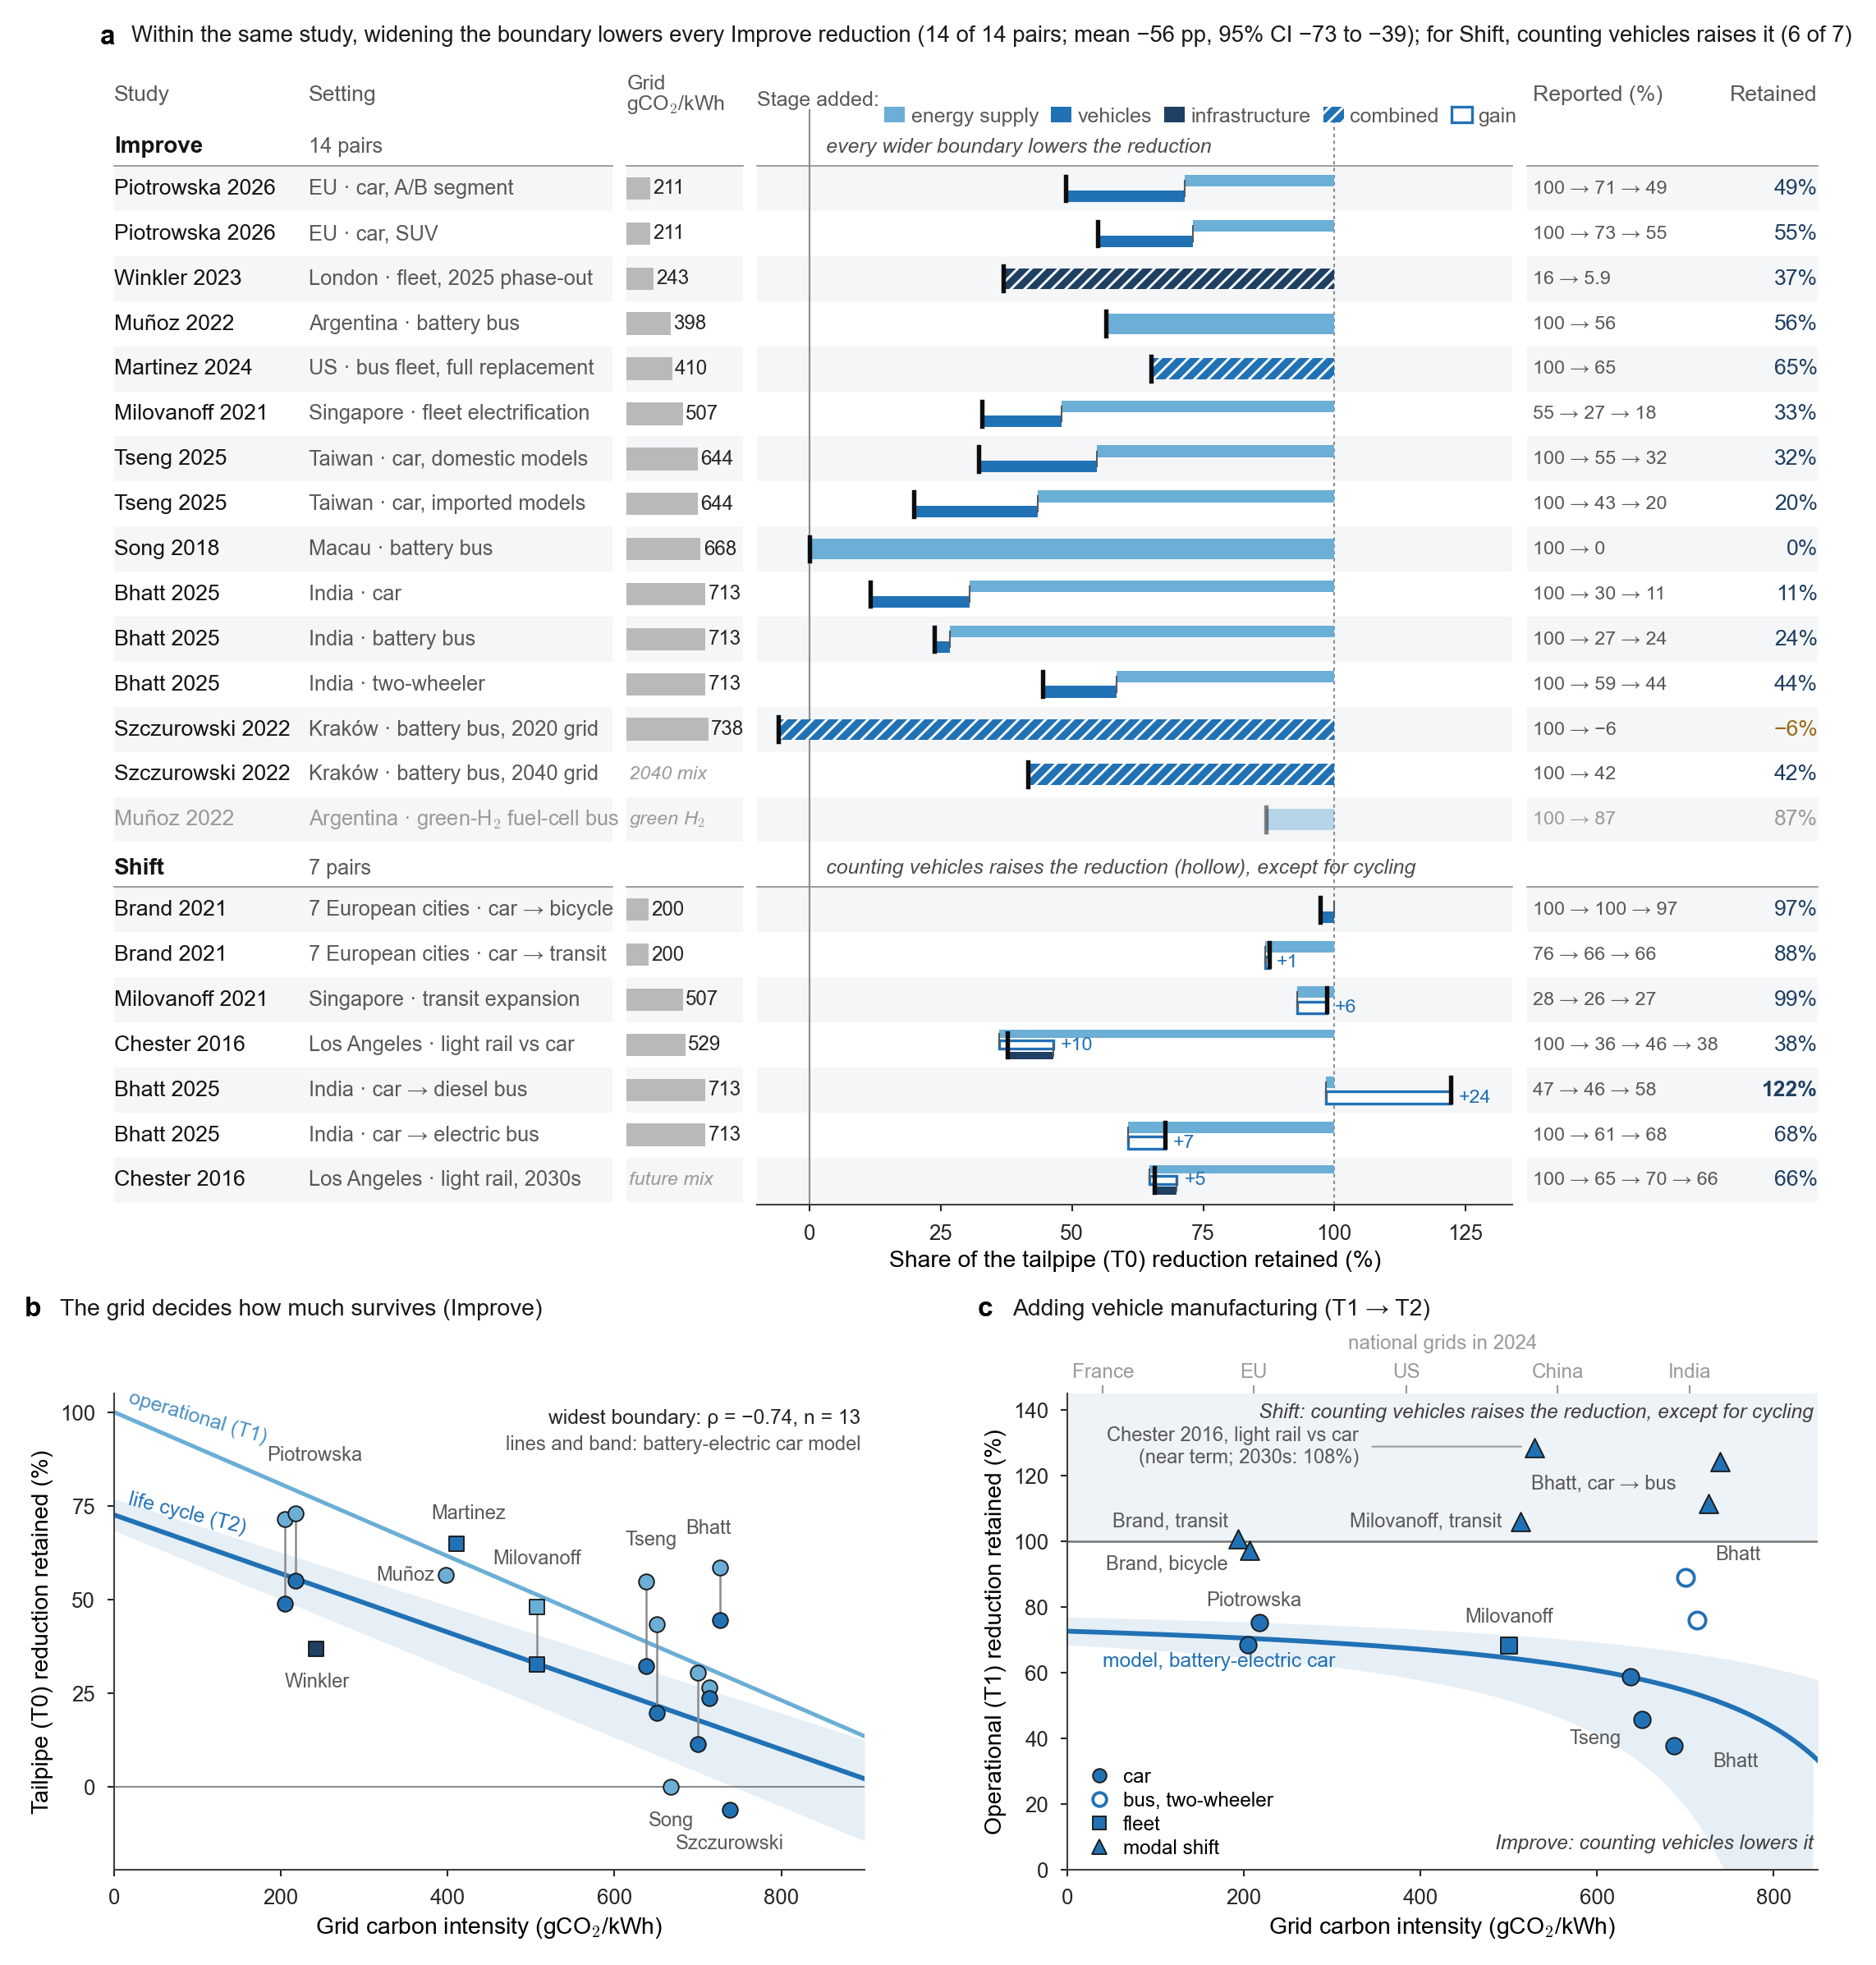

Pairs: 21 from 11 studies | Improve 14 (9 studies) | Shift 7 (4 studies)
Improve, narrowest -> widest: -56.0 pp (95% CI -73.2 to -38.5); retention 0.35 (0.22-0.47); lower in 14 of 14
Improve T0->T1 (pp): -52.06 (95% CI -73.51 to -34.39); 10 pairs, 6 studies; range -100.00 to -26.92
Improve T1->T2 (pp): -15.98 (95% CI -21.74 to -10.22); 8 pairs, 4 studies; range -23.61 to -2.95
Improve T2/T1: 0.65 (95% CI 0.56 to 0.71); 8 pairs, 4 studies; range 0.38 to 0.89
Shift T1->T2 (pp): 4.33 (95% CI 0.22 to 8.43); 7 pairs, 4 studies; range -2.68 to 11.26
Shift T2/T1: 1.10 (95% CI 1.03 to 1.18); 7 pairs, 4 studies; range 0.97 to 1.29
Shift: vehicles raise the reduction in 6 of 7 pairs
Grid (Improve, widest boundary): rho = -0.74, p = 0.004, n = 13; slope = -7.5 pp per 100 gCO2/kWh
Saved: /Users/joanpau/Documents/00_Inbox/Figures Article SLR/Images/Figure_boundary_pairs.{pdf,png,svg} | /Users/joanpau/Documents/00_Inbox/Figures Article SLR/TableS_boundary_pairs.csv


In [1]:
# =====================================================================================================================
# Figure — Within-study boundary pairs (a: where the reduction goes · b: the grid · c: the vehicle-manufacturing step)
# One self-contained notebook cell. Reads study metadata from the SLR data sheet; the stage values of each pair come
# from the full texts (page or figure in `source`) because the sheet records one value per study, not per boundary.
# =====================================================================================================================
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

# ---------------- paths ----------------
DATA = Path("/Users/joanpau/Documents/00_Inbox/Figures Article SLR/SLR_Data_Sheet.xlsx")
OUT_DIR = DATA.parent / "Images" if (DATA.parent / "Images").exists() else DATA.parent
CI_FILE = DATA.parent / "carbon-intensity-electricity.csv"          # Ember via Our World in Data
CI_URL = ("https://ourworldindata.org/grapher/carbon-intensity-electricity.csv"
          "?v=1&csvType=full&useColumnShortNames=false")

# ---------------- 1. study metadata from the data sheet ----------------
SHEET = pd.read_excel(DATA, sheet_name="Extraction")
SHEET["author_clean"] = SHEET["Author"].astype(str).map(lambda s: re.sub(r"\*|\(s\)", "", s).strip())
META = SHEET.set_index("ID")[["author_clean", "Year", "Pillar", "Boundary tier", "Region / country"]]
LABEL = {i: f"{r.author_clean} {int(r.Year)}" for i, r in META.iterrows()}       # e.g. "Milovanoff 2021"
SURNAME = {i: r.author_clean for i, r in META.iterrows()}

# ---------------- 2. grid carbon intensity (gCO2/kWh) ----------------
GRID_FALLBACK = {  # values of the Ember/OWID series used below, for offline use
    ("Singapore", 2018): 507.08, ("European Union (27)", 2024): 211.2, ("United Kingdom", 2020): 242.54,
    ("Argentina", 2019): 397.62, ("Poland", 2020): 738.28, ("China", 2015): 667.85, ("India", 2023): 713.36,
    ("Taiwan", 2023): 644.18, ("United States", 2022): 410.39, ("United States", 2014): 529.41,
    ("France", 2024): 40.48, ("United States", 2024): 383.78, ("China", 2024): 555.4, ("India", 2024): 705.4,
    ("Belgium", 2016): 158.7, ("Spain", 2016): 282.93, ("United Kingdom", 2016): 333.45, ("Sweden", 2016): 42.98,
    ("Italy", 2016): 389.58, ("Austria", 2016): 154.62, ("Switzerland", 2016): 39.44}
try:
    if not CI_FILE.exists():
        pd.read_csv(CI_URL).to_csv(CI_FILE, index=False)
    CI = pd.read_csv(CI_FILE); CI.columns = ["Entity", "Code", "Year", "g"]
except Exception:
    CI = None
def grid(entity, year):
    if CI is not None:
        s = CI[CI["Entity"] == entity].set_index("Year")["g"]
        if len(s):
            return float(s.loc[min(year, s.index.max())])
    return GRID_FALLBACK[(entity, year)]

# ---------------- 3. within-study pairs: % reduction under each boundary (None = not reported) ----------------
# T0 tailpipe · T1 + fuel and electricity supply · T2 + vehicle and battery manufacturing · T3 + infrastructure
BRAND_S4 = {  # Brand et al. 2021, Suppl. Table S4 (g CO2/pkm): car (op, supply, vehicle), public transport (op,
    # supply, vehicle), bicycle/e-bike (supply, vehicle)
    "Antwerp": (141.5, 27.2, 12.9, 14.5, 20.9, 2.9, 0.111, 5.1), "Barcelona": (142.2, 27.5, 10.6, 17.2, 30.5, 3.0, 0.171, 5.1),
    "London": (165.6, 30.4, 12.9, 52.0, 43.5, 3.6, 0.236, 5.1), "Orebro": (153.3, 27.5, 13.2, 68.8, 16.7, 4.2, 0.011, 5.1),
    "Rome": (144.5, 27.7, 11.5, 36.4, 33.9, 3.1, 0.200, 5.1), "Vienna": (156.1, 29.4, 13.3, 24.7, 16.6, 2.8, 0.087, 5.1),
    "Zurich": (143.6, 26.8, 12.5, 43.4, 9.8, 3.4, 0.002, 5.1)}
BRAND_COUNTRIES = ["Belgium", "Spain", "United Kingdom", "Sweden", "Italy", "Austria", "Switzerland"]
def _brand(kind):
    out = []
    for co, cs, cv, po, ps, pv, bs, bv in BRAND_S4.values():
        car = np.cumsum([co, cs, cv])
        alt = np.cumsum([po, ps, pv]) if kind == "pt" else np.cumsum([0.0, bs, bv])
        out.append(100 * (1 - alt / car))
    return dict(zip(["T0", "T1", "T2"], np.mean(out, axis=0).round(2))) | {"T3": None}

P_ = lambda a, b: 100 * (1 - a / b)                     # reduction (%) from scenario and reference emissions
PAIRS = [
    dict(ID="S33", pillar="Improve", unit="fleet", tech="BEV fleet", region=("Singapore", 2018),
         T0=P_(41.7, 93.4), T1=P_(91.9, 125.2), T2=P_(111.4, 136.1), T3=None,
         source="Fig. 3 digitised, PT-Constant -> PT-EV (Mt 2018-2050); text: -25 Mt = 18%"),
    dict(ID="S33", pillar="Shift", unit="fleet", tech="Public transit development", region=("Singapore", 2018),
         T0=P_(93.4, 128.9), T1=P_(125.2, 168.3), T2=P_(136.1, 186.8), T3=None,
         source="Fig. 3 digitised, PC-Constant -> PT-Constant; text: -50 Mt or 27%"),
    dict(ID="S37", pillar="Improve", unit="vehicle", tech="BEV car, A/B segment", region=("European Union (27)", 2024),
         T0=100, T1=P_(1.0, 3.5), T2=P_(2.2, 4.3), T3=None, source="pp. 39-42: WTW and with manufacturing (2025)"),
    dict(ID="S37", pillar="Improve", unit="vehicle", tech="BEV car, SUV", region=("European Union (27)", 2024),
         T0=100, T1=P_(2.1, 7.8), T2=P_(4.1, 9.1), T3=None, source="pp. 39-42: WTW and with manufacturing (2025)"),
    dict(ID="S48", pillar="Improve", unit="fleet", tech="ICE phase-out 2025", region=("United Kingdom", 2020),
         T0=16, T1=None, T2=None, T3=5.9, source="p. 4: tailpipe -16%; cumulative incl. embedded -5.9%"),
    dict(ID="S35", pillar="Improve", unit="vehicle", tech="Battery-electric bus", region=("Argentina", 2019),
         T0=100, T1=56.5, T2=None, T3=None, source="WTW 52-61% vs diesel bus; zero TTW (Fig. 6)"),
    dict(ID="S67", pillar="Improve", unit="vehicle", tech="Electric bus, 2020 grid", region=("Poland", 2020),
         T0=100, T1=None, T2=-6.0, T3=None, source="Results: +6.0% vs diesel bus, 2020 mix"),
    dict(ID="S67", pillar="Improve", unit="vehicle", tech="Electric bus, 2040 grid", region=None,
         T0=100, T1=None, T2=41.6, T3=None, source="Results: -41.6% vs diesel bus, 2040 mix"),
    dict(ID="S65", pillar="Improve", unit="vehicle", tech="Electric bus, current grid", region=("China", 2015),
         T0=100, T1=0.0, T2=None, T3=None, source="Results: no GHG reduction with real charging losses (coded 0)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="BEV car vs diesel car", region=("India", 2023),
         T0=100, T1=P_(65.4, 94.0), T2=P_(107.9, 121.9), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="Electric bus vs diesel bus", region=("India", 2023),
         T0=100, T1=P_(36.9, 50.3), T2=P_(39.3, 51.5), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="Electric vs petrol two-wheeler", region=("India", 2023),
         T0=100, T1=P_(31.1, 75.0), T2=P_(46.1, 83.0), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Shift", unit="mode", tech="Diesel car to electric bus", region=("India", 2023),
         T0=100, T1=P_(36.9, 94.0), T2=P_(39.3, 121.9), T3=None, source="Fig. 3; vs petrol car -72% as in text"),
    dict(ID="S07", pillar="Shift", unit="mode", tech="Diesel car to diesel bus", region=("India", 2023),
         T0=P_(34.7, 65.8), T1=P_(50.3, 94.0), T2=P_(51.5, 121.9), T3=None, source="Fig. 3 digitised"),
    dict(ID="S45", pillar="Improve", unit="vehicle", tech="BEV vs ICEV, domestic", region=("Taiwan", 2023),
         T0=100, T1=P_(0.0816, 0.1805), T2=P_(0.1405, 0.2071), T3=None, source="Fig. 2a digitised (kg/km)"),
    dict(ID="S45", pillar="Improve", unit="vehicle", tech="BEV vs ICEV, imported", region=("Taiwan", 2023),
         T0=100, T1=P_(0.1036, 0.1833), T2=P_(0.1694, 0.2114), T3=None, source="Fig. 2a; text: BEVs ~20% lower"),
    dict(ID="S60", pillar="Improve", unit="fleet", tech="Bus fleet, immediate replacement", region=("United States", 2022),
         T0=100, T1=None, T2=65.0, T3=None, source="p. 4140: 65% of life-cycle GHG avoided"),
    dict(ID="S58", pillar="Shift", unit="mode", tech="Light rail vs car, near term", region=("United States", 2014),
         T0=100, T1=P_(75.7, 118.4), T2=P_(78.7, 146.7), T3=P_(97.4, 156.3), source="Fig. 2 digitised (g CO2e/PKT)"),
    dict(ID="S58", pillar="Shift", unit="mode", tech="Light rail vs car, long term", region=None,
         T0=100, T1=P_(27.5, 78.1), T2=P_(29.8, 99.2), T3=P_(37.5, 109.4), source="Fig. 2, decarbonised mix"),
    dict(ID="S09", pillar="Shift", unit="mode", tech="Car to public transport", region=("BRAND7", 2016),
         **_brand("pt"), source="Suppl. Table S4, mean of 7 cities"),
    dict(ID="S09", pillar="Shift", unit="mode", tech="Car to bicycle", region=("BRAND7", 2016),
         **_brand("bike"), source="Suppl. Table S4, mean of 7 cities"),
    dict(ID="S35", pillar="Improve", unit="vehicle", tech="Green-H2 fuel-cell bus", region=None,
         T0=100, T1=87, T2=None, T3=None, source="87% WTW vs diesel bus (contrast case)"),
]
P = pd.DataFrame(PAIRS)
P["study"] = P["ID"].map(LABEL)
P["grid"] = [np.mean([grid(c, r[1]) for c in BRAND_COUNTRIES]) if r and r[0] == "BRAND7"
             else (grid(*r) if r else np.nan) for r in P["region"]]
P["widest"] = P[["T3", "T2", "T1"]].bfill(axis=1).iloc[:, 0]
P["wide_tier"] = np.where(P["T3"].notna(), "T3", np.where(P["T2"].notna(), "T2", "T1"))
P["retention"] = P["widest"] / P["T0"]
P["delta_pp"] = P["widest"] - P["T0"]
P["ret_T1toT2"] = P["T2"] / P["T1"]

# consistency check against the data sheet (pillar letter and the study's coded boundary tier)
CHK = P.groupby("ID").agg(pillars=("pillar", lambda s: "/".join(sorted(set(s)))), widest=("wide_tier", "max"))
CHK = CHK.join(META[["Pillar", "Boundary tier"]])
CHK["pillar_ok"] = [all(p[0] in str(sp) for p in pl.split("/")) for pl, sp in zip(CHK["pillars"], CHK["Pillar"])]
print(CHK.to_string()); assert CHK["pillar_ok"].all(), "pair pillar not coded for this study in the data sheet"
P.drop(columns=["region"]).to_csv(DATA.parent / "TableS_boundary_pairs.csv", index=False, encoding="utf-8-sig")

# ---------------- 4. statistics (bootstrap over studies, not pairs) ----------------
rng = np.random.default_rng(2026)
def boot_mean(df, col, B=4000):
    per = df.groupby("ID")[col].mean(); ids = df["ID"].unique()      # order of appearance, as in the paper
    bs = [per.loc[rng.choice(ids, len(ids))].mean() for _ in range(B)]
    return per.mean(), np.percentile(bs, [2.5, 97.5]), len(ids)
main = P[~P["tech"].str.contains("H2")]
imp, shf = main[main["pillar"] == "Improve"], main[main["pillar"] == "Shift"]
m_d, ci_d, k = boot_mean(imp, "delta_pp")
m_r, ci_r, _ = boot_mean(imp, "retention")
s12 = shf.dropna(subset=["T1", "T2"]); n_up = int((s12["T2"] > s12["T1"]).sum())

# ---------------- 5. per-vehicle correction model (battery-electric car vs petrol car) ----------------
PARAM = dict(e_ice=177.0, L=198_000.0, m_ice=8.0e6, m_bev=11.8e6, c=0.17)   # Piotrowska 2026; c assumed
def model(g, e_ice=177.0, L=198_000.0, m_ice=8.0e6, m_bev=11.8e6, c=0.17):
    return 1 - c * g / e_ice, 1 - (c * g * L + m_bev) / (e_ice * L + m_ice)
gg = np.linspace(0, 900, 181)
r1c, r2c = model(gg, **PARAM)
GRID_ENV = [(mb, L, c) for mb in (11.8e6, 13.6e6) for L in (198_000.0, 243_580.0) for c in (0.15, 0.20)]
env = np.array([model(gg, L=L, m_bev=mb, c=c)[1] for mb, L, c in GRID_ENV])
renv = 100 * np.array([(lambda a: a[1] / np.where(a[0] > 0.05, a[0], np.nan))(model(gg, L=L, m_bev=mb, c=c))
                       for mb, L, c in GRID_ENV])

# ---------------- 6. figure (180 mm, Nature style) ----------------
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 6.5, "axes.labelsize": 6.8, "xtick.labelsize": 6.2, "ytick.labelsize": 6.2,
                     "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2.0, "ytick.major.size": 2.0, "hatch.linewidth": 0.7,
                     "mathtext.fontset": "cm", "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})
TIER = {"T0": "#c6dbef", "T1": "#6baed6", "T2": "#2171b5", "T3": "#1f3f63"}
TIERS = ["T0", "T1", "T2", "T3"]
SUBTLE, LIGHT, GOLD = "#595959", "#9a9a9a", "#9a6a12"
SETTING = {("S37", "BEV car, SUV"): "EU · car, SUV", ("S37", "BEV car, A/B segment"): "EU · car, A/B segment",
           ("S48", "ICE phase-out 2025"): "London · fleet, 2025 phase-out",
           ("S35", "Battery-electric bus"): "Argentina · battery bus",
           ("S33", "BEV fleet"): "Singapore · fleet electrification",
           ("S65", "Electric bus, current grid"): "Macau · battery bus",
           ("S67", "Electric bus, 2020 grid"): "Kraków · battery bus, 2020 grid",
           ("S67", "Electric bus, 2040 grid"): "Kraków · battery bus, 2040 grid",
           ("S35", "Green-H2 fuel-cell bus"): "Argentina · green-H$_2$ fuel-cell bus",
           ("S07", "BEV car vs diesel car"): "India · car", ("S07", "Electric bus vs diesel bus"): "India · battery bus",
           ("S07", "Electric vs petrol two-wheeler"): "India · two-wheeler",
           ("S45", "BEV vs ICEV, domestic"): "Taiwan · car, domestic models",
           ("S45", "BEV vs ICEV, imported"): "Taiwan · car, imported models",
           ("S60", "Bus fleet, immediate replacement"): "US · bus fleet, full replacement",
           ("S58", "Light rail vs car, near term"): "Los Angeles · light rail vs car",
           ("S58", "Light rail vs car, long term"): "Los Angeles · light rail, 2030s",
           ("S33", "Public transit development"): "Singapore · transit expansion",
           ("S07", "Diesel car to electric bus"): "India · car → electric bus",
           ("S07", "Diesel car to diesel bus"): "India · car → diesel bus",
           ("S09", "Car to public transport"): "7 European cities · car → transit",
           ("S09", "Car to bicycle"): "7 European cities · car → bicycle"}
GRID_NOTE = {"Electric bus, 2040 grid": "2040 mix", "Green-H2 fuel-cell bus": "green H$_2$",
             "Light rail vs car, long term": "future mix"}
fmt = lambda v: (f"{v:.0f}" if abs(v - round(v)) < 0.05 or abs(v) >= 10 else f"{v:.1f}").replace("-", "−")
mns = lambda v: f"{v:.0f}".replace("-", "−")
def clean(ax, left=True):
    for s_ in ["top", "right"] + ([] if left else ["left"]):
        ax.spines[s_].set_visible(False)
    for s_ in ["left", "bottom"]:
        ax.spines[s_].set_color("0.25")
    ax.tick_params(colors="0.15", direction="out")

fig = plt.figure(figsize=(180 / 25.4, 8.1), dpi=300)
outer = gridspec.GridSpec(2, 1, height_ratios=[2.3, 1.0], hspace=0.24, left=0.012, right=0.988, top=0.936,
                          bottom=0.054)
top = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[0], width_ratios=[0.30, 0.07, 0.455, 0.175],
                                       wspace=0.035)
bot = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[1], width_ratios=[1, 1], wspace=0.27)
ax_lab, ax_g, ax_a, ax_t = (fig.add_subplot(top[i]) for i in range(4))
ax_b, ax_c = fig.add_subplot(bot[0]), fig.add_subplot(bot[1])

# ---- a: where the tailpipe reduction goes, stage by stage ----
R = P.assign(order=np.where(P["tech"].str.contains("H2"), 9e9, P["grid"].fillna(8e9)))
R = R.sort_values(["order", "study", "tech"]).reset_index(drop=True)
BLOCK_NOTE = {"Improve": "every wider boundary lowers the reduction",
              "Shift": "counting vehicles raises the reduction (hollow), except for cycling"}
slots = []
for pil in ["Improve", "Shift"]:
    sub = R[R["pillar"] == pil]
    slots.append(("hdr", pil, len(sub) - int(sub["tech"].str.contains("H2").sum())))
    slots += [("row", r) for _, r in sub.iterrows()]
n = len(slots)
for ax in (ax_lab, ax_g, ax_a, ax_t):
    ax.set_ylim(n - 0.45, -0.75)
for ax in (ax_lab, ax_t):
    ax.axis("off")
k_row = 0
for y, slot in enumerate(slots):
    if slot[0] == "hdr":
        tr = ax_lab.get_yaxis_transform()
        ax_lab.text(0.0, y + 0.08, slot[1], va="center", fontsize=6.7, fontweight="bold", color="0.08", transform=tr)
        ax_lab.text(0.39, y + 0.08, f"{slot[2]} pairs", va="center", fontsize=6.1, color=SUBTLE, transform=tr)
        ax_a.text(3, y + 0.08, BLOCK_NOTE[slot[1]], va="center", fontsize=6.0, color="0.3", style="italic")
        for ax in (ax_lab, ax_g, ax_a, ax_t):
            ax.plot([0, 1], [y + 0.5, y + 0.5], color="0.55", linewidth=0.4, transform=ax.get_yaxis_transform(),
                    clip_on=False, zorder=1)
        k_row = 0
        continue
    r = slot[1]; grey = "H2" in r["tech"]; k_row += 1
    if k_row % 2 == 1:
        for ax in (ax_lab, ax_g, ax_a, ax_t):
            ax.axhspan(y - 0.5, y + 0.5, color="#f4f6f8", zorder=0, linewidth=0)
    tr = ax_lab.get_yaxis_transform()
    ax_lab.text(0.0, y, r["study"], va="center", fontsize=6.4, color=LIGHT if grey else "0.08", transform=tr)
    ax_lab.text(0.39, y, SETTING[(r["ID"], r["tech"])], va="center", fontsize=6.1, color=LIGHT if grey else SUBTLE,
                transform=tr)
    if pd.notna(r["grid"]):
        ax_g.barh(y, r["grid"], height=0.5, color="#b9b9b9", edgecolor="none", zorder=2)
        ax_g.text(r["grid"] + 25, y, f"{r['grid']:.0f}", va="center", fontsize=5.8, color="0.15")
    else:
        ax_g.text(20, y, GRID_NOTE.get(r["tech"], "–"), va="center", fontsize=5.6, color=LIGHT, style="italic")
    pts = [(t, r[t]) for t in TIERS if pd.notna(r[t])]
    lv = [(t, 100 * v / pts[0][1]) for t, v in pts]               # normalised to the tailpipe (T0) reduction
    steps = list(zip(lv[:-1], lv[1:]))
    offs = [0.0] if len(steps) == 1 else list(np.linspace(-0.17, 0.17, 2) if len(steps) == 2
                                              else np.linspace(-0.24, 0.24, len(steps)))
    hgt = 0.46 if len(steps) == 1 else (0.26 if len(steps) == 2 else 0.18)
    for k_, ((ta, a), (tb, b)) in enumerate(steps):
        combined = TIERS.index(tb) - TIERS.index(ta) > 1
        if b > a:     # the added stage RAISES the reduction: hollow bar
            ax_a.barh(y + offs[k_], b - a, left=a, height=hgt, color="white", edgecolor=TIER[tb], linewidth=0.8,
                      zorder=3)
            ax_a.text(b + 1.5, y + offs[k_], f"+{b - a:.0f}", va="center", fontsize=5.6, color=TIER["T2"])
        else:
            ax_a.barh(y + offs[k_], a - b, left=b, height=hgt, color=TIER[tb], edgecolor="white" if combined else "none",
                      linewidth=0, hatch="//////" if combined else None, alpha=0.45 if grey else 1, zorder=3)
        if k_ > 0:
            ax_a.plot([a, a], [y + offs[k_ - 1], y + offs[k_]], color="0.35", linewidth=0.5, zorder=4)
    final = lv[-1][1]
    ax_a.plot([final, final], [y - 0.27, y + 0.27], color="0.05", linewidth=1.3, zorder=5, alpha=0.5 if grey else 1)
    ax_t.text(0.02, y, " → ".join(fmt(v) for _, v in pts), va="center", fontsize=5.6, color=LIGHT if grey else SUBTLE,
              transform=ax_t.get_yaxis_transform())
    ax_t.text(1.0, y, f"{fmt(final)}%", ha="right", va="center", fontsize=6.4, transform=ax_t.get_yaxis_transform(),
              color=LIGHT if grey else (GOLD if final < 0 else "#1f3f63"), fontweight="bold" if final > 100 else "normal")
ax_a.axvline(0, color="0.55", linewidth=0.5, zorder=1)
ax_a.axvline(100, color="0.55", linewidth=0.5, zorder=1, linestyle=(0, (2, 2)))
ax_a.set_xlim(-10, 134); ax_a.set_xticks([0, 25, 50, 75, 100, 125]); ax_a.set_yticks([])
clean(ax_a, left=False)
ax_a.set_xlabel("Share of the tailpipe (T0) reduction retained (%)", labelpad=2)
ax_g.set_xlim(0, 1050); ax_g.set_xticks([]); ax_g.set_yticks([])
for s_ in ax_g.spines.values():
    s_.set_visible(False)
hy = -1.08
ax_lab.text(0.0, hy, "Study", fontsize=6.4, color=SUBTLE, va="center", transform=ax_lab.get_yaxis_transform())
ax_lab.text(0.39, hy, "Setting", fontsize=6.4, color=SUBTLE, va="center", transform=ax_lab.get_yaxis_transform())
ax_g.text(0, hy, "Grid\ngCO$_2$/kWh", fontsize=6.0, color=SUBTLE, va="center", linespacing=1.0)
ax_t.text(0.02, hy, "Reported (%)", fontsize=6.4, color=SUBTLE, va="center", transform=ax_t.get_yaxis_transform())
ax_t.text(1.0, hy, "Retained", fontsize=6.4, color=SUBTLE, va="center", ha="right", transform=ax_t.get_yaxis_transform())
stage_h = [Patch(facecolor=TIER["T1"], edgecolor="none", label="energy supply"),
           Patch(facecolor=TIER["T2"], edgecolor="none", label="vehicles"),
           Patch(facecolor=TIER["T3"], edgecolor="none", label="infrastructure"),
           Patch(facecolor=TIER["T2"], edgecolor="white", linewidth=0, hatch="//////", label="combined"),
           Patch(facecolor="white", edgecolor=TIER["T2"], linewidth=0.8, label="gain")]
ax_a.text(0.0, 1.0, "Stage added:", transform=ax_a.transAxes, fontsize=6.0, color=SUBTLE, va="bottom")
ax_a.legend(handles=stage_h, loc="lower left", bbox_to_anchor=(0.168, 0.985), ncol=5, frameon=False, fontsize=6.0,
            handlelength=1.0, handleheight=0.8, handletextpad=0.3, columnspacing=0.6, borderaxespad=0, borderpad=0,
            labelcolor=SUBTLE)
SUMMARY_A = (f"Within the same study, widening the boundary lowers every Improve reduction "
             f"({int((imp['delta_pp'] < 0).sum())} of {len(imp)} pairs; mean {mns(m_d)} pp, 95% CI {mns(ci_d[0])} to "
             f"{mns(ci_d[1])}); for Shift, counting vehicles raises it ({n_up} of {len(s12)})")

# ---- b: the grid decides how much survives (Improve) ----
B = P[(P["pillar"] == "Improve") & ~P["tech"].str.contains("H2") & P["grid"].notna()].copy()
ax_b.fill_between(gg, 100 * env.min(0), 100 * env.max(0), color="#2171b5", alpha=0.11, linewidth=0, zorder=1)
ax_b.plot(gg, 100 * r1c, color="#6baed6", linewidth=1.2, zorder=2)
ax_b.plot(gg, 100 * r2c, color="#2171b5", linewidth=1.4, zorder=2)
ax_b.text(15, 100 * model(15, **PARAM)[0] + 3, "operational (T1)", color="#4a90c4", fontsize=5.9, rotation=-16.5,
          rotation_mode="anchor", va="bottom")
ax_b.text(15, 100 * model(15, **PARAM)[1] + 3, "life cycle (T2)", color="#2171b5", fontsize=5.9, rotation=-14,
          rotation_mode="anchor", va="bottom")
B["xj"] = B["grid"] + B.groupby("grid").cumcount() * 13 - (B.groupby("grid")["grid"].transform("size") - 1) * 6.5
for _, r in B.iterrows():
    mk = {"vehicle": "o", "fleet": "s"}[r["unit"]]
    pts = [(t, 100 * r[t] / r["T0"]) for t in ["T1", "T2", "T3"] if pd.notna(r[t])]
    if len(pts) > 1:
        ax_b.plot([r["xj"]] * len(pts), [v for _, v in pts], color="0.55", linewidth=0.6, zorder=3)
    for t, v in pts:
        ax_b.scatter(r["xj"], v, s=20, marker=mk, color=TIER[t], edgecolor="0.1", linewidth=0.45, zorder=4)
LAB_B = {"S37": (240, 88.5, "center"), "S48": (243, 28, "center"), "S35": (384, 56.5, "right"),
         "S60": (425, 73, "center"), "S33": (507, 61, "center"), "S45": (644, 66, "center"), "S65": (668, -9, "center"),
         "S07": (713, 69, "center"), "S67": (738, -15, "center")}
for i, (x_, y_, ha) in LAB_B.items():
    ax_b.text(x_, y_, SURNAME[i], fontsize=5.7, color=SUBTLE, ha=ha, va="center")
rb, pb = stats.spearmanr(B["grid"], B["retention"])
ax_b.axhline(0, color="0.55", linewidth=0.5, zorder=0)
ax_b.set_xlim(0, 900); ax_b.set_ylim(-22, 105)
ax_b.set_xticks(range(0, 901, 200)); ax_b.set_yticks(range(0, 101, 25))
ax_b.set_xlabel("Grid carbon intensity (gCO$_2$/kWh)", labelpad=2)
ax_b.set_ylabel("Tailpipe (T0) reduction retained (%)", labelpad=2)
clean(ax_b)
ax_b.text(895, 101, f"widest boundary: ρ = {rb:.2f}, n = {len(B)}".replace("-", "−"), ha="right", va="top",
          fontsize=5.9, color="0.15")
ax_b.text(895, 94, "lines and band: battery-electric car model", ha="right", va="top", fontsize=5.7, color=SUBTLE)

# ---- c: the vehicle-manufacturing step (T1 -> T2) ----
Cc = P[P["T1"].notna() & P["T2"].notna()].copy()
Cc["r12"] = 100 * Cc["T2"] / Cc["T1"]
ratio = r2c / np.where(r1c > 0.05, r1c, np.nan)
ax_c.axhspan(100, 145, color="#eef3f8", linewidth=0, zorder=0)
ax_c.axhline(100, color="0.45", linewidth=0.6, zorder=1)
ax_c.fill_between(gg, np.nanmin(renv, 0), np.nanmax(renv, 0), color="#2171b5", alpha=0.11, linewidth=0, zorder=1)
ax_c.plot(gg, 100 * ratio, color="#2171b5", linewidth=1.4, zorder=2)
ax_c.text(40, 100 * ratio[np.searchsorted(gg, 40)] - 6, "model, battery-electric car", color="#2171b5", fontsize=5.9,
          va="top")
Co = Cc[Cc["grid"].notna()].copy()
Co["xj"] = Co["grid"] + Co.groupby("grid").cumcount() * 13 - (Co.groupby("grid")["grid"].transform("size") - 1) * 6.5
for _, r in Co.iterrows():
    is_car = r["unit"] == "vehicle" and not any(w in r["tech"] for w in ["bus", "two-wheeler"])
    mk = "^" if r["pillar"] == "Shift" else {"vehicle": "o", "fleet": "s"}[r["unit"]]
    solid = is_car or r["unit"] in ("fleet", "mode") or r["pillar"] == "Shift"
    ax_c.scatter(r["xj"], r["r12"], s=24 if mk != "^" else 30, marker=mk, color=TIER["T2"] if solid else "white",
                 edgecolor="0.1" if solid else TIER["T2"], linewidth=0.45 if solid else 0.9, zorder=4)
lt = Cc[(Cc["unit"] == "mode") & Cc["grid"].isna()]
ax_c.annotate(f"{LABEL['S58']}, light rail vs car\n(near term; 2030s: {fmt(lt['r12'].iloc[0])}%)", (522, 128.8),
              xytext=(330, 128.8), fontsize=5.7, color=SUBTLE, ha="right", va="center",
              arrowprops=dict(arrowstyle="-", color=LIGHT, linewidth=0.5))
for x_, y_, i in [(211, 82, "S37"), (500, 77, "S33"), (598, 40, "S45"), (760, 96, "S07"), (757, 33, "S07")]:
    ax_c.text(x_, y_, SURNAME[i], fontsize=5.7, color=SUBTLE, ha="center", va="center")
for x_, y_, lab in [(492, 106.0, f"{SURNAME['S33']}, transit"), (690, 117.5, f"{SURNAME['S07']}, car → bus"),
                    (182, 106.0, f"{SURNAME['S09']}, transit"), (182, 93.0, f"{SURNAME['S09']}, bicycle")]:
    ax_c.text(x_, y_, lab, fontsize=5.7, color=SUBTLE, ha="right", va="center")
ax_c.text(845, 142, "Shift: counting vehicles raises the reduction, except for cycling", fontsize=5.9, color="0.25",
          ha="right", va="top", style="italic")
ax_c.text(845, 5, "Improve: counting vehicles lowers it", fontsize=5.9, color="0.25", ha="right", va="bottom",
          style="italic")
ax_c.set_xlim(0, 850); ax_c.set_ylim(0, 145)
ax_c.set_xticks(range(0, 801, 200)); ax_c.set_yticks(range(0, 141, 20))
ax_c.set_xlabel("Grid carbon intensity (gCO$_2$/kWh)", labelpad=2)
ax_c.set_ylabel("Operational (T1) reduction retained (%)", labelpad=2)
clean(ax_c)
sec = ax_c.secondary_xaxis("top")
CTRY = [("France", "France"), ("European Union (27)", "EU"), ("United States", "US"), ("China", "China"), ("India", "India")]
sec.set_xticks([grid(e, 2024) for e, _ in CTRY]); sec.set_xticklabels([l for _, l in CTRY], fontsize=5.8, color=LIGHT)
sec.tick_params(length=2.5, color=LIGHT, pad=1); sec.spines["top"].set_visible(False)
sec.set_xlabel("national grids in 2024", fontsize=5.8, color=LIGHT, labelpad=4)
mk_h = [Line2D([0], [0], marker="o", ls="none", ms=4, mfc=TIER["T2"], mec="0.1", mew=0.45, label="car"),
        Line2D([0], [0], marker="o", ls="none", ms=4, mfc="white", mec=TIER["T2"], mew=0.9, label="bus, two-wheeler"),
        Line2D([0], [0], marker="s", ls="none", ms=3.8, mfc=TIER["T2"], mec="0.1", mew=0.45, label="fleet"),
        Line2D([0], [0], marker="^", ls="none", ms=4.3, mfc=TIER["T2"], mec="0.1", mew=0.45, label="modal shift")]
ax_c.legend(handles=mk_h, loc="lower left", frameon=False, fontsize=5.8, handletextpad=0.2, borderaxespad=0.2,
            labelspacing=0.25)

# ---- letters and panel titles ----
fig.canvas.draw()
inv = fig.transFigure.inverted()
fig.text(0.004, 0.966, "a", fontsize=8, fontweight="bold", va="bottom")
fig.text(0.022, 0.9675, SUMMARY_A, fontsize=6.6, color="0.1", va="bottom")
y_bc = max(inv.transform(a_.get_tightbbox(fig.canvas.get_renderer()))[1][1] for a_ in (ax_b, ax_c)) + 0.006
for ax_, letter, title in [(ax_b, "b", "The grid decides how much survives (Improve)"),
                           (ax_c, "c", "Adding vehicle manufacturing (T1 → T2)")]:
    x0 = inv.transform(ax_.get_tightbbox(fig.canvas.get_renderer()))[0][0]
    fig.text(x0 - 0.004, y_bc, letter, fontsize=8, fontweight="bold", va="bottom")
    fig.text(x0 + 0.016, y_bc + 0.001, title, fontsize=6.8, color="0.1", va="bottom")
for ext, dpi in [("pdf", 300), ("png", 600), ("svg", 300)]:
    fig.savefig(OUT_DIR / f"Figure_boundary_pairs.{ext}", dpi=dpi, bbox_inches="tight", facecolor="white")
plt.show()

# ---------------- 7. numbers for the Results text ----------------
t01 = imp.dropna(subset=["T1"]).assign(d=lambda x: x["T1"] - x["T0"])
t12 = imp.dropna(subset=["T1", "T2"]).assign(d=lambda x: x["T2"] - x["T1"], r=lambda x: x["T2"] / x["T1"])
sh12 = s12.assign(d=lambda x: x["T2"] - x["T1"], r=lambda x: x["T2"] / x["T1"])
print(f"Pairs: {len(main)} from {main['ID'].nunique()} studies | Improve {len(imp)} ({k} studies) | "
      f"Shift {len(shf)} ({shf['ID'].nunique()} studies)")
print(f"Improve, narrowest -> widest: {m_d:+.1f} pp (95% CI {ci_d[0]:+.1f} to {ci_d[1]:+.1f}); retention "
      f"{m_r:.2f} ({ci_r[0]:.2f}-{ci_r[1]:.2f}); lower in {int((imp['delta_pp'] < 0).sum())} of {len(imp)}")
for lab, df, col in [("Improve T0->T1 (pp)", t01, "d"), ("Improve T1->T2 (pp)", t12, "d"),
                     ("Improve T2/T1", t12, "r"), ("Shift T1->T2 (pp)", sh12, "d"), ("Shift T2/T1", sh12, "r")]:
    m, ci, kk = boot_mean(df, col)
    print(f"{lab}: {m:.2f} (95% CI {ci[0]:.2f} to {ci[1]:.2f}); {len(df)} pairs, {kk} studies; "
          f"range {df[col].min():.2f} to {df[col].max():.2f}")
print(f"Shift: vehicles raise the reduction in {n_up} of {len(s12)} pairs")
print(f"Grid (Improve, widest boundary): rho = {rb:.2f}, p = {pb:.3f}, n = {len(B)}; "
      f"slope = {100 * np.polyfit(B['grid'] / 100, B['retention'], 1)[0]:.1f} pp per 100 gCO2/kWh")
print("Saved:", OUT_DIR / "Figure_boundary_pairs.{pdf,png,svg}", "|", DATA.parent / "TableS_boundary_pairs.csv")


           pillars widest Pillar Boundary tier  pillar_ok
ID                                                       
S07  Improve/Shift     T2    S+I            T3       True
S09          Shift     T2      S            T2       True
S33  Improve/Shift     T2  A+S+I            T2       True
S35        Improve     T1      I            T1       True
S37        Improve     T2      I            T2       True
S45        Improve     T2      I            T2       True
S48        Improve     T3  A+S+I            T3       True
S58          Shift     T3      S            T3       True
S60        Improve     T2      I            T2       True
S65        Improve     T1      I            T1       True
S67        Improve     T2      I            T2       True


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


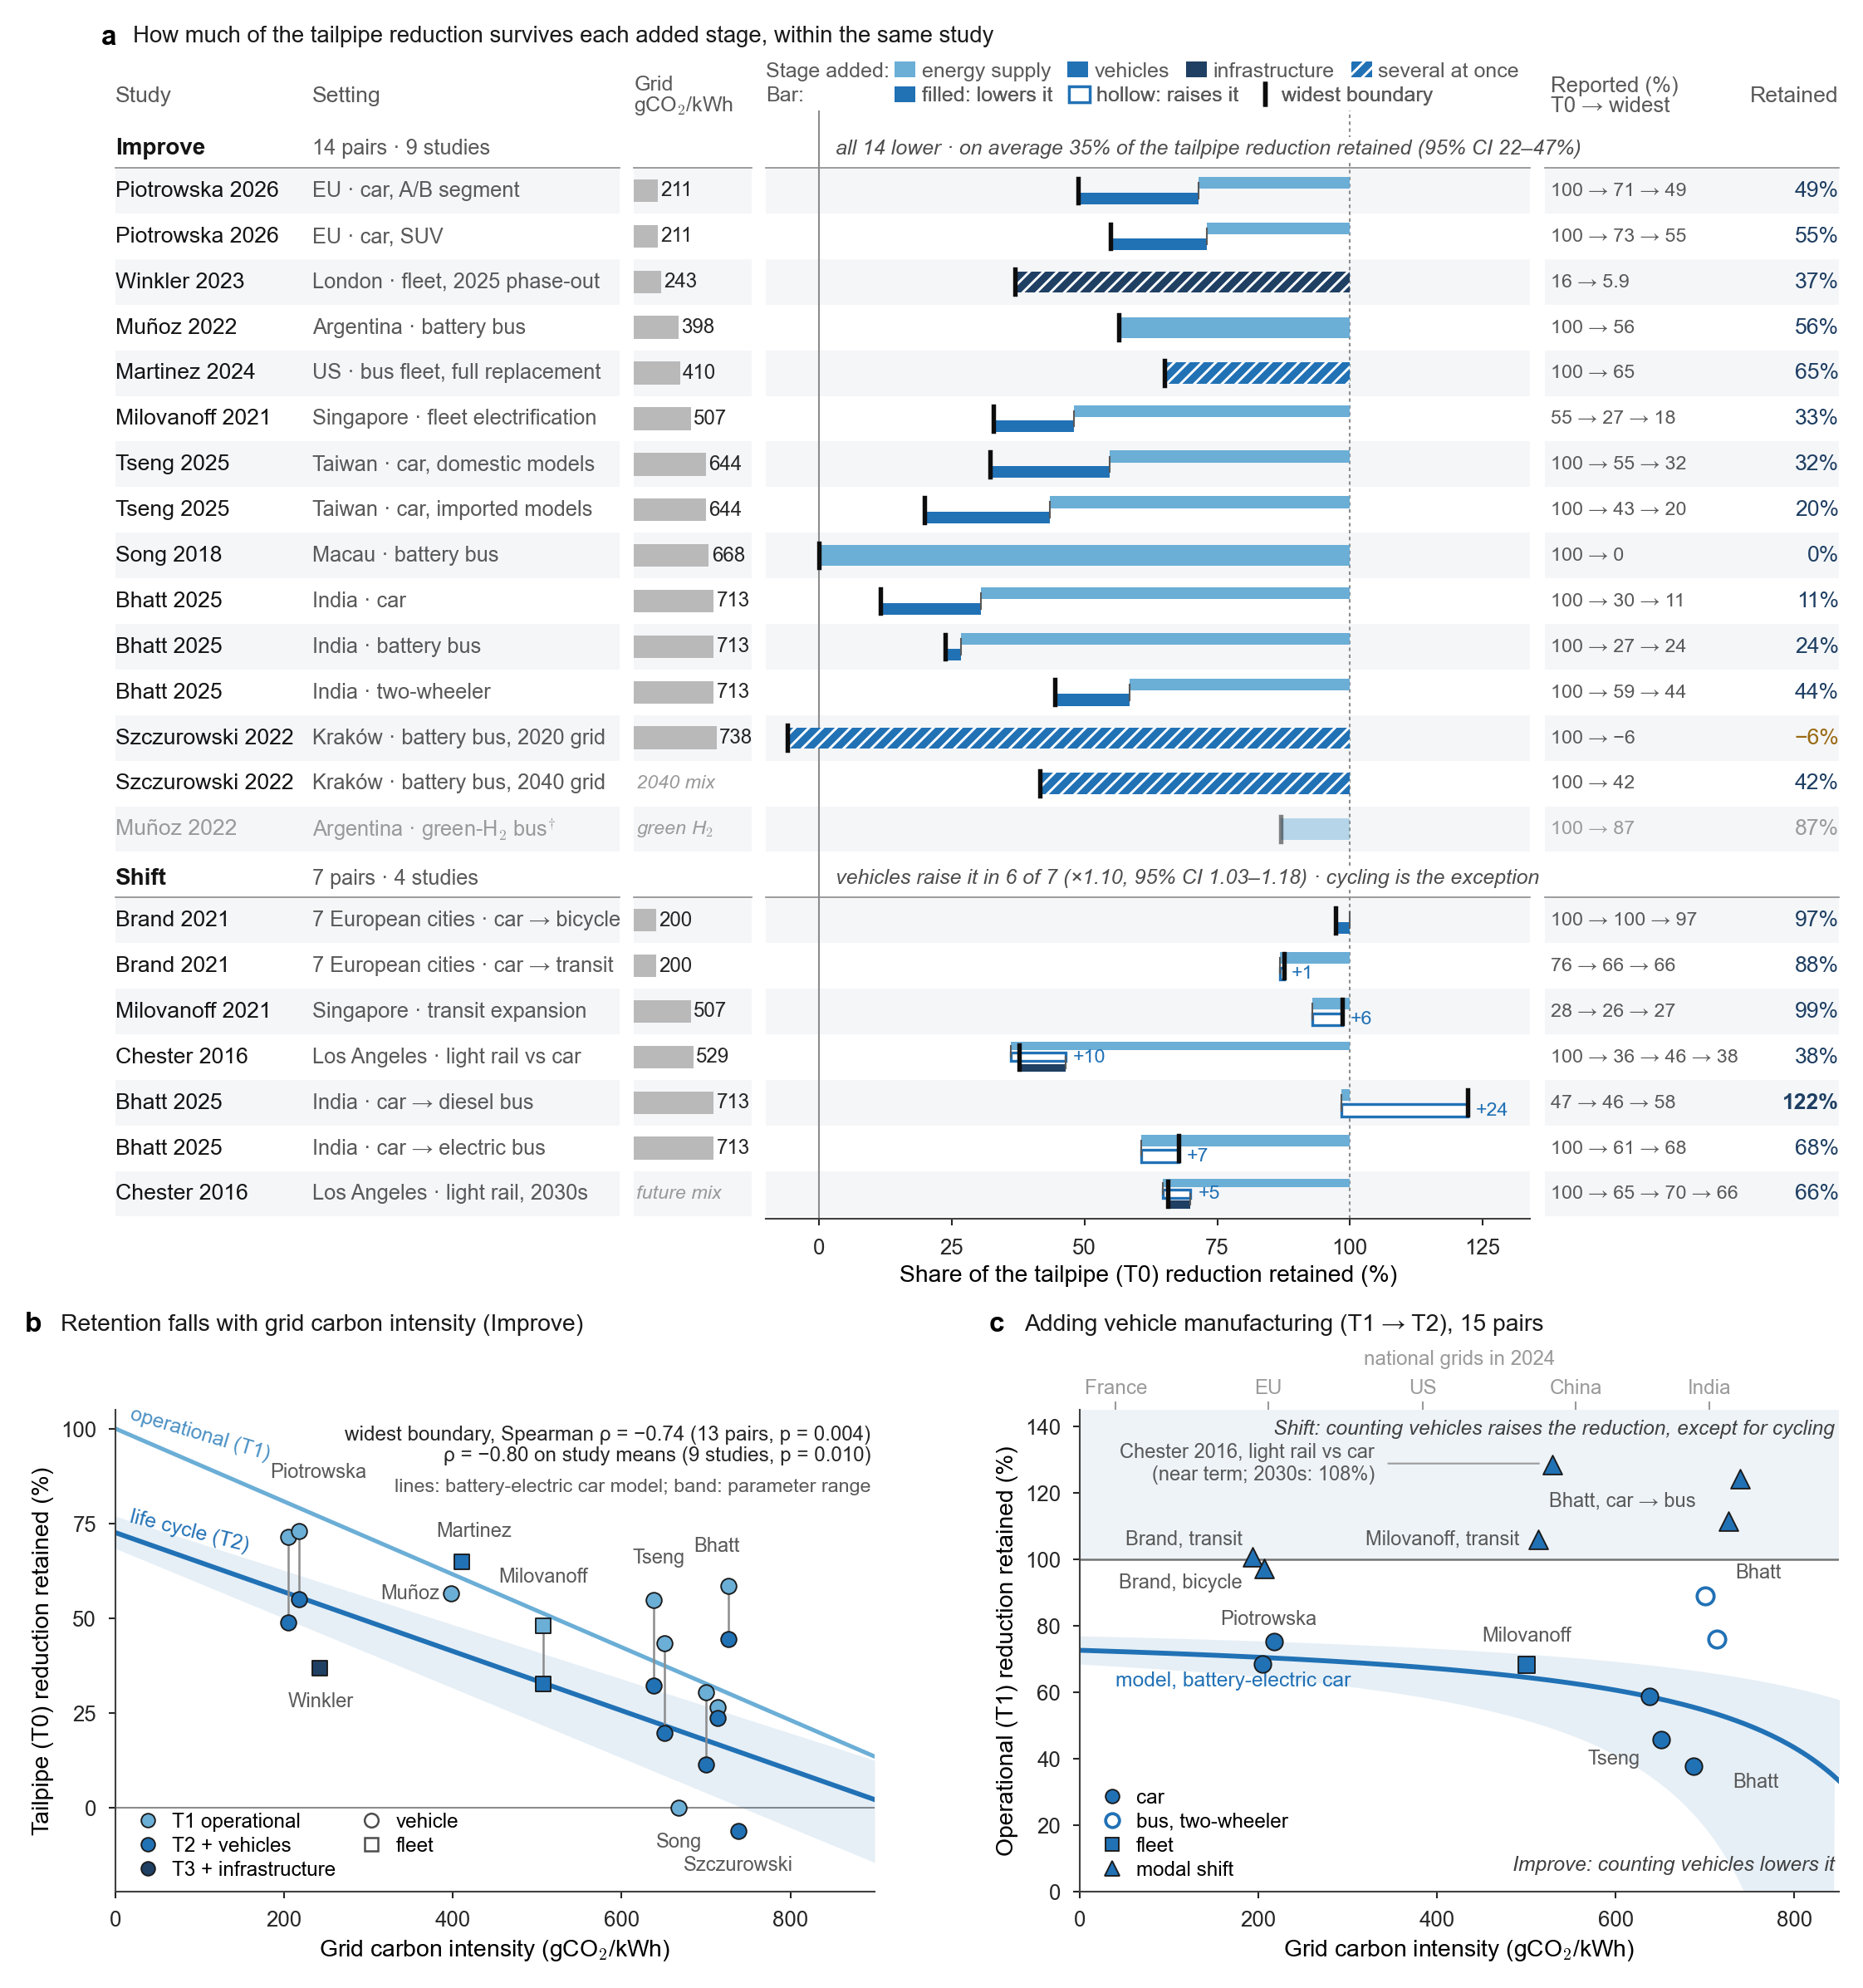

Pairs: 21 from 11 studies | Improve 14 (9 studies) | Shift 7 (4 studies)
Improve, narrowest -> widest: -56.0 pp (95% CI -73.2 to -38.5); retention 0.35 (0.22-0.47); lower in 14 of 14
Improve T0->T1 (pp): -52.06 (95% CI -73.51 to -34.39); 10 pairs, 6 studies; range -100.00 to -26.92
Improve T1->T2 (pp): -15.98 (95% CI -21.74 to -10.22); 8 pairs, 4 studies; range -23.61 to -2.95
Improve T2/T1: 0.65 (95% CI 0.56 to 0.71); 8 pairs, 4 studies; range 0.38 to 0.89
Shift T1->T2 (pp): 4.33 (95% CI 0.22 to 8.43); 7 pairs, 4 studies; range -2.68 to 11.26
Shift T2/T1: 1.10 (95% CI 1.03 to 1.18); 7 pairs, 4 studies; range 0.97 to 1.29
Shift: vehicles raise the reduction in 6 of 7 pairs
Grid (Improve, widest boundary): rho = -0.74, p = 0.004, n = 13; slope = -7.5 pp per 100 gCO2/kWh
Saved: /Users/joanpau/Documents/00_Inbox/Figures Article SLR/Images/Figure_boundary_pairs.{pdf,png,svg} | /Users/joanpau/Documents/00_Inbox/Figures Article SLR/TableS_boundary_pairs.csv


In [2]:
# =====================================================================================================================
# Figure — Within-study boundary pairs (a: where the reduction goes · b: the grid · c: the vehicle-manufacturing step)
# One self-contained notebook cell. Reads study metadata from the SLR data sheet; the stage values of each pair come
# from the full texts (page or figure in `source`) because the sheet records one value per study, not per boundary.
# =====================================================================================================================
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

# ---------------- paths ----------------
DATA = Path("/Users/joanpau/Documents/00_Inbox/Figures Article SLR/SLR_Data_Sheet.xlsx")
OUT_DIR = DATA.parent / "Images" if (DATA.parent / "Images").exists() else DATA.parent
CI_FILE = DATA.parent / "carbon-intensity-electricity.csv"          # Ember via Our World in Data
CI_URL = ("https://ourworldindata.org/grapher/carbon-intensity-electricity.csv"
          "?v=1&csvType=full&useColumnShortNames=false")

# ---------------- 1. study metadata from the data sheet ----------------
SHEET = pd.read_excel(DATA, sheet_name="Extraction")
SHEET["author_clean"] = SHEET["Author"].astype(str).map(lambda s: re.sub(r"\*|\(s\)", "", s).strip())
META = SHEET.set_index("ID")[["author_clean", "Year", "Pillar", "Boundary tier", "Region / country"]]
LABEL = {i: f"{r.author_clean} {int(r.Year)}" for i, r in META.iterrows()}       # e.g. "Milovanoff 2021"
SURNAME = {i: r.author_clean for i, r in META.iterrows()}

# ---------------- 2. grid carbon intensity (gCO2/kWh) ----------------
GRID_FALLBACK = {  # values of the Ember/OWID series used below, for offline use
    ("Singapore", 2018): 507.08, ("European Union (27)", 2024): 211.2, ("United Kingdom", 2020): 242.54,
    ("Argentina", 2019): 397.62, ("Poland", 2020): 738.28, ("China", 2015): 667.85, ("India", 2023): 713.36,
    ("Taiwan", 2023): 644.18, ("United States", 2022): 410.39, ("United States", 2014): 529.41,
    ("France", 2024): 40.48, ("United States", 2024): 383.78, ("China", 2024): 555.4, ("India", 2024): 705.4,
    ("Belgium", 2016): 158.7, ("Spain", 2016): 282.93, ("United Kingdom", 2016): 333.45, ("Sweden", 2016): 42.98,
    ("Italy", 2016): 389.58, ("Austria", 2016): 154.62, ("Switzerland", 2016): 39.44}
try:
    if not CI_FILE.exists():
        pd.read_csv(CI_URL).to_csv(CI_FILE, index=False)
    CI = pd.read_csv(CI_FILE); CI.columns = ["Entity", "Code", "Year", "g"]
except Exception:
    CI = None
def grid(entity, year):
    if CI is not None:
        s = CI[CI["Entity"] == entity].set_index("Year")["g"]
        if len(s):
            return float(s.loc[min(year, s.index.max())])
    return GRID_FALLBACK[(entity, year)]

# ---------------- 3. within-study pairs: % reduction under each boundary (None = not reported) ----------------
# T0 tailpipe · T1 + fuel and electricity supply · T2 + vehicle and battery manufacturing · T3 + infrastructure
BRAND_S4 = {  # Brand et al. 2021, Suppl. Table S4 (g CO2/pkm): car (op, supply, vehicle), public transport (op,
    # supply, vehicle), bicycle/e-bike (supply, vehicle)
    "Antwerp": (141.5, 27.2, 12.9, 14.5, 20.9, 2.9, 0.111, 5.1), "Barcelona": (142.2, 27.5, 10.6, 17.2, 30.5, 3.0, 0.171, 5.1),
    "London": (165.6, 30.4, 12.9, 52.0, 43.5, 3.6, 0.236, 5.1), "Orebro": (153.3, 27.5, 13.2, 68.8, 16.7, 4.2, 0.011, 5.1),
    "Rome": (144.5, 27.7, 11.5, 36.4, 33.9, 3.1, 0.200, 5.1), "Vienna": (156.1, 29.4, 13.3, 24.7, 16.6, 2.8, 0.087, 5.1),
    "Zurich": (143.6, 26.8, 12.5, 43.4, 9.8, 3.4, 0.002, 5.1)}
BRAND_COUNTRIES = ["Belgium", "Spain", "United Kingdom", "Sweden", "Italy", "Austria", "Switzerland"]
def _brand(kind):
    out = []
    for co, cs, cv, po, ps, pv, bs, bv in BRAND_S4.values():
        car = np.cumsum([co, cs, cv])
        alt = np.cumsum([po, ps, pv]) if kind == "pt" else np.cumsum([0.0, bs, bv])
        out.append(100 * (1 - alt / car))
    return dict(zip(["T0", "T1", "T2"], np.mean(out, axis=0).round(2))) | {"T3": None}

P_ = lambda a, b: 100 * (1 - a / b)                     # reduction (%) from scenario and reference emissions
PAIRS = [
    dict(ID="S33", pillar="Improve", unit="fleet", tech="BEV fleet", region=("Singapore", 2018),
         T0=P_(41.7, 93.4), T1=P_(91.9, 125.2), T2=P_(111.4, 136.1), T3=None,
         source="Fig. 3 digitised, PT-Constant -> PT-EV (Mt 2018-2050); text: -25 Mt = 18%"),
    dict(ID="S33", pillar="Shift", unit="fleet", tech="Public transit development", region=("Singapore", 2018),
         T0=P_(93.4, 128.9), T1=P_(125.2, 168.3), T2=P_(136.1, 186.8), T3=None,
         source="Fig. 3 digitised, PC-Constant -> PT-Constant; text: -50 Mt or 27%"),
    dict(ID="S37", pillar="Improve", unit="vehicle", tech="BEV car, A/B segment", region=("European Union (27)", 2024),
         T0=100, T1=P_(1.0, 3.5), T2=P_(2.2, 4.3), T3=None, source="pp. 39-42: WTW and with manufacturing (2025)"),
    dict(ID="S37", pillar="Improve", unit="vehicle", tech="BEV car, SUV", region=("European Union (27)", 2024),
         T0=100, T1=P_(2.1, 7.8), T2=P_(4.1, 9.1), T3=None, source="pp. 39-42: WTW and with manufacturing (2025)"),
    dict(ID="S48", pillar="Improve", unit="fleet", tech="ICE phase-out 2025", region=("United Kingdom", 2020),
         T0=16, T1=None, T2=None, T3=5.9, source="p. 4: tailpipe -16%; cumulative incl. embedded -5.9%"),
    dict(ID="S35", pillar="Improve", unit="vehicle", tech="Battery-electric bus", region=("Argentina", 2019),
         T0=100, T1=56.5, T2=None, T3=None, source="WTW 52-61% vs diesel bus; zero TTW (Fig. 6)"),
    dict(ID="S67", pillar="Improve", unit="vehicle", tech="Electric bus, 2020 grid", region=("Poland", 2020),
         T0=100, T1=None, T2=-6.0, T3=None, source="Results: +6.0% vs diesel bus, 2020 mix"),
    dict(ID="S67", pillar="Improve", unit="vehicle", tech="Electric bus, 2040 grid", region=None,
         T0=100, T1=None, T2=41.6, T3=None, source="Results: -41.6% vs diesel bus, 2040 mix"),
    dict(ID="S65", pillar="Improve", unit="vehicle", tech="Electric bus, current grid", region=("China", 2015),
         T0=100, T1=0.0, T2=None, T3=None, source="Results: no GHG reduction with real charging losses (coded 0)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="BEV car vs diesel car", region=("India", 2023),
         T0=100, T1=P_(65.4, 94.0), T2=P_(107.9, 121.9), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="Electric bus vs diesel bus", region=("India", 2023),
         T0=100, T1=P_(36.9, 50.3), T2=P_(39.3, 51.5), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Improve", unit="vehicle", tech="Electric vs petrol two-wheeler", region=("India", 2023),
         T0=100, T1=P_(31.1, 75.0), T2=P_(46.1, 83.0), T3=None, source="Fig. 3 digitised (g CO2e/pkm)"),
    dict(ID="S07", pillar="Shift", unit="mode", tech="Diesel car to electric bus", region=("India", 2023),
         T0=100, T1=P_(36.9, 94.0), T2=P_(39.3, 121.9), T3=None, source="Fig. 3; vs petrol car -72% as in text"),
    dict(ID="S07", pillar="Shift", unit="mode", tech="Diesel car to diesel bus", region=("India", 2023),
         T0=P_(34.7, 65.8), T1=P_(50.3, 94.0), T2=P_(51.5, 121.9), T3=None, source="Fig. 3 digitised"),
    dict(ID="S45", pillar="Improve", unit="vehicle", tech="BEV vs ICEV, domestic", region=("Taiwan", 2023),
         T0=100, T1=P_(0.0816, 0.1805), T2=P_(0.1405, 0.2071), T3=None, source="Fig. 2a digitised (kg/km)"),
    dict(ID="S45", pillar="Improve", unit="vehicle", tech="BEV vs ICEV, imported", region=("Taiwan", 2023),
         T0=100, T1=P_(0.1036, 0.1833), T2=P_(0.1694, 0.2114), T3=None, source="Fig. 2a; text: BEVs ~20% lower"),
    dict(ID="S60", pillar="Improve", unit="fleet", tech="Bus fleet, immediate replacement", region=("United States", 2022),
         T0=100, T1=None, T2=65.0, T3=None, source="p. 4140: 65% of life-cycle GHG avoided"),
    dict(ID="S58", pillar="Shift", unit="mode", tech="Light rail vs car, near term", region=("United States", 2014),
         T0=100, T1=P_(75.7, 118.4), T2=P_(78.7, 146.7), T3=P_(97.4, 156.3), source="Fig. 2 digitised (g CO2e/PKT)"),
    dict(ID="S58", pillar="Shift", unit="mode", tech="Light rail vs car, long term", region=None,
         T0=100, T1=P_(27.5, 78.1), T2=P_(29.8, 99.2), T3=P_(37.5, 109.4), source="Fig. 2, decarbonised mix"),
    dict(ID="S09", pillar="Shift", unit="mode", tech="Car to public transport", region=("BRAND7", 2016),
         **_brand("pt"), source="Suppl. Table S4, mean of 7 cities"),
    dict(ID="S09", pillar="Shift", unit="mode", tech="Car to bicycle", region=("BRAND7", 2016),
         **_brand("bike"), source="Suppl. Table S4, mean of 7 cities"),
    dict(ID="S35", pillar="Improve", unit="vehicle", tech="Green-H2 fuel-cell bus", region=None,
         T0=100, T1=87, T2=None, T3=None, source="87% WTW vs diesel bus (contrast case)"),
]
P = pd.DataFrame(PAIRS)
P["study"] = P["ID"].map(LABEL)
P["grid"] = [np.mean([grid(c, r[1]) for c in BRAND_COUNTRIES]) if r and r[0] == "BRAND7"
             else (grid(*r) if r else np.nan) for r in P["region"]]
P["widest"] = P[["T3", "T2", "T1"]].bfill(axis=1).iloc[:, 0]
P["wide_tier"] = np.where(P["T3"].notna(), "T3", np.where(P["T2"].notna(), "T2", "T1"))
P["retention"] = P["widest"] / P["T0"]
P["delta_pp"] = P["widest"] - P["T0"]
P["ret_T1toT2"] = P["T2"] / P["T1"]

# consistency check against the data sheet (pillar letter and the study's coded boundary tier)
CHK = P.groupby("ID").agg(pillars=("pillar", lambda s: "/".join(sorted(set(s)))), widest=("wide_tier", "max"))
CHK = CHK.join(META[["Pillar", "Boundary tier"]])
CHK["pillar_ok"] = [all(p[0] in str(sp) for p in pl.split("/")) for pl, sp in zip(CHK["pillars"], CHK["Pillar"])]
print(CHK.to_string()); assert CHK["pillar_ok"].all(), "pair pillar not coded for this study in the data sheet"
P.drop(columns=["region"]).to_csv(DATA.parent / "TableS_boundary_pairs.csv", index=False, encoding="utf-8-sig")

# ---------------- 4. statistics (bootstrap over studies, not pairs) ----------------
rng = np.random.default_rng(2026)
def boot_mean(df, col, B=4000):
    per = df.groupby("ID")[col].mean(); ids = df["ID"].unique()      # order of appearance, as in the paper
    bs = [per.loc[rng.choice(ids, len(ids))].mean() for _ in range(B)]
    return per.mean(), np.percentile(bs, [2.5, 97.5]), len(ids)
main = P[~P["tech"].str.contains("H2")]
imp, shf = main[main["pillar"] == "Improve"], main[main["pillar"] == "Shift"]
m_d, ci_d, k = boot_mean(imp, "delta_pp")
m_r, ci_r, _ = boot_mean(imp, "retention")
s12 = shf.dropna(subset=["T1", "T2"]); n_up = int((s12["T2"] > s12["T1"]).sum())
t01 = imp.dropna(subset=["T1"]).assign(d=lambda x: x["T1"] - x["T0"])
t12 = imp.dropna(subset=["T1", "T2"]).assign(d=lambda x: x["T2"] - x["T1"], r=lambda x: x["T2"] / x["T1"])
sh12 = s12.assign(d=lambda x: x["T2"] - x["T1"], r=lambda x: x["T2"] / x["T1"])
STEP = {lab: (df, col, *boot_mean(df, col)) for lab, df, col in [
    ("Improve T0->T1 (pp)", t01, "d"), ("Improve T1->T2 (pp)", t12, "d"), ("Improve T2/T1", t12, "r"),
    ("Shift T1->T2 (pp)", sh12, "d"), ("Shift T2/T1", sh12, "r")]}

# ---------------- 5. per-vehicle correction model (battery-electric car vs petrol car) ----------------
PARAM = dict(e_ice=177.0, L=198_000.0, m_ice=8.0e6, m_bev=11.8e6, c=0.17)   # Piotrowska 2026; c assumed
def model(g, e_ice=177.0, L=198_000.0, m_ice=8.0e6, m_bev=11.8e6, c=0.17):
    return 1 - c * g / e_ice, 1 - (c * g * L + m_bev) / (e_ice * L + m_ice)
gg = np.linspace(0, 900, 181)
r1c, r2c = model(gg, **PARAM)
GRID_ENV = [(mb, L, c) for mb in (11.8e6, 13.6e6) for L in (198_000.0, 243_580.0) for c in (0.15, 0.20)]
env = np.array([model(gg, L=L, m_bev=mb, c=c)[1] for mb, L, c in GRID_ENV])
renv = 100 * np.array([(lambda a: a[1] / np.where(a[0] > 0.05, a[0], np.nan))(model(gg, L=L, m_bev=mb, c=c))
                       for mb, L, c in GRID_ENV])

# ---------------- 6. figure (180 mm, Nature style) ----------------
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 6.5, "axes.labelsize": 6.8, "xtick.labelsize": 6.2, "ytick.labelsize": 6.2,
                     "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2.0, "ytick.major.size": 2.0, "hatch.linewidth": 0.7,
                     "mathtext.fontset": "cm", "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})
TIER = {"T0": "#c6dbef", "T1": "#6baed6", "T2": "#2171b5", "T3": "#1f3f63"}
TIERS = ["T0", "T1", "T2", "T3"]
SUBTLE, LIGHT, GOLD = "#595959", "#9a9a9a", "#9a6a12"
SETTING = {("S37", "BEV car, SUV"): "EU · car, SUV", ("S37", "BEV car, A/B segment"): "EU · car, A/B segment",
           ("S48", "ICE phase-out 2025"): "London · fleet, 2025 phase-out",
           ("S35", "Battery-electric bus"): "Argentina · battery bus",
           ("S33", "BEV fleet"): "Singapore · fleet electrification",
           ("S65", "Electric bus, current grid"): "Macau · battery bus",
           ("S67", "Electric bus, 2020 grid"): "Kraków · battery bus, 2020 grid",
           ("S67", "Electric bus, 2040 grid"): "Kraków · battery bus, 2040 grid",
           ("S35", "Green-H2 fuel-cell bus"): "Argentina · green-H$_2$ bus$^{\\dagger}$",
           ("S07", "BEV car vs diesel car"): "India · car", ("S07", "Electric bus vs diesel bus"): "India · battery bus",
           ("S07", "Electric vs petrol two-wheeler"): "India · two-wheeler",
           ("S45", "BEV vs ICEV, domestic"): "Taiwan · car, domestic models",
           ("S45", "BEV vs ICEV, imported"): "Taiwan · car, imported models",
           ("S60", "Bus fleet, immediate replacement"): "US · bus fleet, full replacement",
           ("S58", "Light rail vs car, near term"): "Los Angeles · light rail vs car",
           ("S58", "Light rail vs car, long term"): "Los Angeles · light rail, 2030s",
           ("S33", "Public transit development"): "Singapore · transit expansion",
           ("S07", "Diesel car to electric bus"): "India · car → electric bus",
           ("S07", "Diesel car to diesel bus"): "India · car → diesel bus",
           ("S09", "Car to public transport"): "7 European cities · car → transit",
           ("S09", "Car to bicycle"): "7 European cities · car → bicycle"}
GRID_NOTE = {"Electric bus, 2040 grid": "2040 mix", "Green-H2 fuel-cell bus": "green H$_2$",
             "Light rail vs car, long term": "future mix"}
fmt = lambda v: (f"{v:.0f}" if abs(v - round(v)) < 0.05 or abs(v) >= 10 else f"{v:.1f}").replace("-", "−")
mns = lambda v: f"{v:.0f}".replace("-", "−")
def clean(ax, left=True):
    for s_ in ["top", "right"] + ([] if left else ["left"]):
        ax.spines[s_].set_visible(False)
    for s_ in ["left", "bottom"]:
        ax.spines[s_].set_color("0.25")
    ax.tick_params(colors="0.15", direction="out")

fig = plt.figure(figsize=(180 / 25.4, 8.1), dpi=300)
outer = gridspec.GridSpec(2, 1, height_ratios=[2.3, 1.0], hspace=0.24, left=0.012, right=0.988, top=0.936,
                          bottom=0.054)
top = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[0], width_ratios=[0.30, 0.07, 0.455, 0.175],
                                       wspace=0.035)
bot = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[1], width_ratios=[1, 1], wspace=0.27)
ax_lab, ax_g, ax_a, ax_t = (fig.add_subplot(top[i]) for i in range(4))
ax_b, ax_c = fig.add_subplot(bot[0]), fig.add_subplot(bot[1])

# ---- a: where the tailpipe reduction goes, stage by stage ----
R = P.assign(order=np.where(P["tech"].str.contains("H2"), 9e9, P["grid"].fillna(8e9)))
R = R.sort_values(["order", "study", "tech"]).reset_index(drop=True)
_ms = STEP["Shift T2/T1"]
BLOCK_NOTE = {"Improve": (f"all {len(imp)} lower · on average {100 * m_r:.0f}% of the tailpipe reduction retained "
                          f"(95% CI {100 * ci_r[0]:.0f}–{100 * ci_r[1]:.0f}%)"),
              "Shift": (f"vehicles raise it in {n_up} of {len(s12)} (×{_ms[2]:.2f}, 95% CI {_ms[3][0]:.2f}–"
                        f"{_ms[3][1]:.2f}) · cycling is the exception")}
N_STUDIES = {"Improve": imp["ID"].nunique(), "Shift": shf["ID"].nunique()}
slots = []
for pil in ["Improve", "Shift"]:
    sub = R[R["pillar"] == pil]
    slots.append(("hdr", pil, len(sub) - int(sub["tech"].str.contains("H2").sum())))
    slots += [("row", r) for _, r in sub.iterrows()]
n = len(slots)
for ax in (ax_lab, ax_g, ax_a, ax_t):
    ax.set_ylim(n - 0.45, -0.75)
for ax in (ax_lab, ax_t):
    ax.axis("off")
k_row = 0
for y, slot in enumerate(slots):
    if slot[0] == "hdr":
        tr = ax_lab.get_yaxis_transform()
        ax_lab.text(0.0, y + 0.08, slot[1], va="center", fontsize=6.7, fontweight="bold", color="0.08", transform=tr)
        ax_lab.text(0.39, y + 0.08, f"{slot[2]} pairs · {N_STUDIES[slot[1]]} studies", va="center", fontsize=6.1,
                    color=SUBTLE, transform=tr)
        ax_a.text(3, y + 0.08, BLOCK_NOTE[slot[1]], va="center", fontsize=6.0, color="0.3", style="italic",
                  zorder=6, bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
        for ax in (ax_lab, ax_g, ax_a, ax_t):
            ax.plot([0, 1], [y + 0.5, y + 0.5], color="0.55", linewidth=0.4, transform=ax.get_yaxis_transform(),
                    clip_on=False, zorder=1)
        k_row = 0
        continue
    r = slot[1]; grey = "H2" in r["tech"]; k_row += 1
    if k_row % 2 == 1:
        for ax in (ax_lab, ax_g, ax_a, ax_t):
            ax.axhspan(y - 0.5, y + 0.5, color="#f4f6f8", zorder=0, linewidth=0)
    tr = ax_lab.get_yaxis_transform()
    ax_lab.text(0.0, y, r["study"], va="center", fontsize=6.4, color=LIGHT if grey else "0.08", transform=tr)
    ax_lab.text(0.39, y, SETTING[(r["ID"], r["tech"])], va="center", fontsize=6.1, color=LIGHT if grey else SUBTLE,
                transform=tr)
    if pd.notna(r["grid"]):
        ax_g.barh(y, r["grid"], height=0.5, color="#b9b9b9", edgecolor="none", zorder=2)
        ax_g.text(r["grid"] + 25, y, f"{r['grid']:.0f}", va="center", fontsize=5.8, color="0.15")
    else:
        ax_g.text(20, y, GRID_NOTE.get(r["tech"], "–"), va="center", fontsize=5.6, color=LIGHT, style="italic")
    pts = [(t, r[t]) for t in TIERS if pd.notna(r[t])]
    lv = [(t, 100 * v / pts[0][1]) for t, v in pts]               # normalised to the tailpipe (T0) reduction
    steps = list(zip(lv[:-1], lv[1:]))
    offs = [0.0] if len(steps) == 1 else list(np.linspace(-0.17, 0.17, 2) if len(steps) == 2
                                              else np.linspace(-0.24, 0.24, len(steps)))
    hgt = 0.46 if len(steps) == 1 else (0.26 if len(steps) == 2 else 0.18)
    for k_, ((ta, a), (tb, b)) in enumerate(steps):
        combined = TIERS.index(tb) - TIERS.index(ta) > 1
        if b > a:     # the added stage RAISES the reduction: hollow bar
            ax_a.barh(y + offs[k_], b - a, left=a, height=hgt, color="white", edgecolor=TIER[tb], linewidth=0.8,
                      zorder=3)
            ax_a.text(b + 1.5, y + offs[k_], f"+{b - a:.0f}", va="center", fontsize=5.6, color=TIER["T2"])
        else:
            ax_a.barh(y + offs[k_], a - b, left=b, height=hgt, color=TIER[tb], edgecolor="white" if combined else "none",
                      linewidth=0, hatch="//////" if combined else None, alpha=0.45 if grey else 1, zorder=3)
        if k_ > 0:
            ax_a.plot([a, a], [y + offs[k_ - 1], y + offs[k_]], color="0.35", linewidth=0.5, zorder=4)
    final = lv[-1][1]
    ax_a.plot([final, final], [y - 0.27, y + 0.27], color="0.05", linewidth=1.3, zorder=5, alpha=0.5 if grey else 1)
    ax_t.text(0.02, y, " → ".join(fmt(v) for _, v in pts), va="center", fontsize=5.6, color=LIGHT if grey else SUBTLE,
              transform=ax_t.get_yaxis_transform())
    ax_t.text(1.0, y, f"{fmt(final)}%", ha="right", va="center", fontsize=6.4, transform=ax_t.get_yaxis_transform(),
              color=LIGHT if grey else (GOLD if final < 0 else "#1f3f63"), fontweight="bold" if final > 100 else "normal")
ax_a.axvline(0, color="0.55", linewidth=0.5, zorder=1)
ax_a.axvline(100, color="0.55", linewidth=0.5, zorder=1, linestyle=(0, (2, 2)))
ax_a.set_xlim(-10, 134); ax_a.set_xticks([0, 25, 50, 75, 100, 125]); ax_a.set_yticks([])
clean(ax_a, left=False)
ax_a.set_xlabel("Share of the tailpipe (T0) reduction retained (%)", labelpad=2)
ax_g.set_xlim(0, 1050); ax_g.set_xticks([]); ax_g.set_yticks([])
for s_ in ax_g.spines.values():
    s_.set_visible(False)
hy = -1.08
ax_lab.text(0.0, hy, "Study", fontsize=6.4, color=SUBTLE, va="center", transform=ax_lab.get_yaxis_transform())
ax_lab.text(0.39, hy, "Setting", fontsize=6.4, color=SUBTLE, va="center", transform=ax_lab.get_yaxis_transform())
ax_g.text(0, hy, "Grid\ngCO$_2$/kWh", fontsize=6.0, color=SUBTLE, va="center", linespacing=1.0)
ax_t.text(0.02, hy, "Reported (%)\nT0 → widest", fontsize=6.2, color=SUBTLE, va="center", linespacing=1.0,
          transform=ax_t.get_yaxis_transform())
ax_t.text(1.0, hy, "Retained", fontsize=6.4, color=SUBTLE, va="center", ha="right", transform=ax_t.get_yaxis_transform())
stage_h = [Patch(facecolor=TIER["T1"], edgecolor="none", label="energy supply"),
           Patch(facecolor=TIER["T2"], edgecolor="none", label="vehicles"),
           Patch(facecolor=TIER["T3"], edgecolor="none", label="infrastructure"),
           Patch(facecolor=TIER["T2"], edgecolor="white", linewidth=0, hatch="//////", label="several at once")]
code_h = [Patch(facecolor=TIER["T2"], edgecolor="none", label="filled: lowers it"),
          Patch(facecolor="white", edgecolor=TIER["T2"], linewidth=0.8, label="hollow: raises it"),
          Line2D([0], [0], color="0.05", marker="|", markersize=7, markeredgewidth=1.3, linestyle="none",
                 label="widest boundary")]
YT = ax_a.get_yaxis_transform()
for y_leg, lab, hs in [(-1.62, "Stage added:", stage_h), (-1.08, "Bar:", code_h)]:
    ax_a.text(0.0, y_leg, lab, transform=YT, fontsize=6.0, color=SUBTLE, va="center")
    leg = ax_a.legend(handles=hs, loc="center left", bbox_to_anchor=(0.168, y_leg),
                      bbox_transform=YT, ncol=len(hs), frameon=False, fontsize=6.0, handlelength=1.0,
                      handleheight=0.8, handletextpad=0.3, columnspacing=0.8, borderaxespad=0, borderpad=0,
                      labelcolor=SUBTLE)
    ax_a.add_artist(leg)
SUMMARY_A = "How much of the tailpipe reduction survives each added stage, within the same study"

# ---- b: the grid decides how much survives (Improve) ----
B = P[(P["pillar"] == "Improve") & ~P["tech"].str.contains("H2") & P["grid"].notna()].copy()
ax_b.fill_between(gg, 100 * env.min(0), 100 * env.max(0), color="#2171b5", alpha=0.11, linewidth=0, zorder=1)
ax_b.plot(gg, 100 * r1c, color="#6baed6", linewidth=1.2, zorder=2)
ax_b.plot(gg, 100 * r2c, color="#2171b5", linewidth=1.4, zorder=2)
ax_b.text(15, 100 * model(15, **PARAM)[0] + 3, "operational (T1)", color="#4a90c4", fontsize=5.9, rotation=-16.5,
          rotation_mode="anchor", va="bottom")
ax_b.text(15, 100 * model(15, **PARAM)[1] + 3, "life cycle (T2)", color="#2171b5", fontsize=5.9, rotation=-14,
          rotation_mode="anchor", va="bottom")
B["xj"] = B["grid"] + B.groupby("grid").cumcount() * 13 - (B.groupby("grid")["grid"].transform("size") - 1) * 6.5
for _, r in B.iterrows():
    mk = {"vehicle": "o", "fleet": "s"}[r["unit"]]
    pts = [(t, 100 * r[t] / r["T0"]) for t in ["T1", "T2", "T3"] if pd.notna(r[t])]
    if len(pts) > 1:
        ax_b.plot([r["xj"]] * len(pts), [v for _, v in pts], color="0.55", linewidth=0.6, zorder=3)
    for t, v in pts:
        ax_b.scatter(r["xj"], v, s=20, marker=mk, color=TIER[t], edgecolor="0.1", linewidth=0.45, zorder=4)
LAB_B = {"S37": (240, 88.5, "center"), "S48": (243, 28, "center"), "S35": (384, 56.5, "right"),
         "S60": (425, 73, "center"), "S33": (507, 61, "center"), "S45": (644, 66, "center"), "S65": (668, -9, "center"),
         "S07": (713, 69, "center"), "S67": (738, -15, "center")}
for i, (x_, y_, ha) in LAB_B.items():
    ax_b.text(x_, y_, SURNAME[i], fontsize=5.7, color=SUBTLE, ha=ha, va="center")
rb, pb = stats.spearmanr(B["grid"], B["retention"])
BS = B.groupby("ID")[["grid", "retention"]].mean()
rbs, pbs = stats.spearmanr(BS["grid"], BS["retention"])
b_h = [Line2D([0], [0], marker="o", ls="none", ms=4, mfc=TIER[t], mec="0.1", mew=0.45, label=l)
       for t, l in [("T1", "T1 operational"), ("T2", "T2 + vehicles"), ("T3", "T3 + infrastructure")]] + \
      [Line2D([0], [0], marker="o", ls="none", ms=4, mfc="white", mec="0.3", mew=0.6, label="vehicle"),
       Line2D([0], [0], marker="s", ls="none", ms=3.8, mfc="white", mec="0.3", mew=0.6, label="fleet")]
ax_b.legend(handles=b_h, loc="lower left", ncol=2, frameon=False, fontsize=5.8, handletextpad=0.2,
            columnspacing=0.8, borderaxespad=0.2, labelspacing=0.25)
ax_b.axhline(0, color="0.55", linewidth=0.5, zorder=0)
ax_b.set_xlim(0, 900); ax_b.set_ylim(-22, 105)
ax_b.set_xticks(range(0, 901, 200)); ax_b.set_yticks(range(0, 101, 25))
ax_b.set_xlabel("Grid carbon intensity (gCO$_2$/kWh)", labelpad=2)
ax_b.set_ylabel("Tailpipe (T0) reduction retained (%)", labelpad=2)
clean(ax_b)
ax_b.text(895, 101, (f"widest boundary, Spearman ρ = {rb:.2f} ({len(B)} pairs, p = {pb:.3f})\n"
                    f"ρ = {rbs:.2f} on study means ({len(BS)} studies, p = {pbs:.3f})").replace("-", "−"),
          ha="right", va="top", fontsize=5.8, color="0.15", linespacing=1.15)
ax_b.text(895, 87, "lines: battery-electric car model; band: parameter range", ha="right", va="top", fontsize=5.6,
          color=SUBTLE)

# ---- c: the vehicle-manufacturing step (T1 -> T2) ----
Cc = P[P["T1"].notna() & P["T2"].notna()].copy()
Cc["r12"] = 100 * Cc["T2"] / Cc["T1"]
ratio = r2c / np.where(r1c > 0.05, r1c, np.nan)
ax_c.axhspan(100, 145, color="#eef3f8", linewidth=0, zorder=0)
ax_c.axhline(100, color="0.45", linewidth=0.6, zorder=1)
ax_c.fill_between(gg, np.nanmin(renv, 0), np.nanmax(renv, 0), color="#2171b5", alpha=0.11, linewidth=0, zorder=1)
ax_c.plot(gg, 100 * ratio, color="#2171b5", linewidth=1.4, zorder=2)
ax_c.text(40, 100 * ratio[np.searchsorted(gg, 40)] - 6, "model, battery-electric car", color="#2171b5", fontsize=5.9,
          va="top")
Co = Cc[Cc["grid"].notna()].copy()
Co["xj"] = Co["grid"] + Co.groupby("grid").cumcount() * 13 - (Co.groupby("grid")["grid"].transform("size") - 1) * 6.5
for _, r in Co.iterrows():
    is_car = r["unit"] == "vehicle" and not any(w in r["tech"] for w in ["bus", "two-wheeler"])
    mk = "^" if r["pillar"] == "Shift" else {"vehicle": "o", "fleet": "s"}[r["unit"]]
    solid = is_car or r["unit"] in ("fleet", "mode") or r["pillar"] == "Shift"
    ax_c.scatter(r["xj"], r["r12"], s=24 if mk != "^" else 30, marker=mk, color=TIER["T2"] if solid else "white",
                 edgecolor="0.1" if solid else TIER["T2"], linewidth=0.45 if solid else 0.9, zorder=4)
lt = Cc[(Cc["unit"] == "mode") & Cc["grid"].isna()]
ax_c.annotate(f"{LABEL['S58']}, light rail vs car\n(near term; 2030s: {fmt(lt['r12'].iloc[0])}%)", (522, 128.8),
              xytext=(330, 128.8), fontsize=5.7, color=SUBTLE, ha="right", va="center",
              arrowprops=dict(arrowstyle="-", color=LIGHT, linewidth=0.5))
for x_, y_, i in [(211, 82, "S37"), (500, 77, "S33"), (598, 40, "S45"), (760, 96, "S07"), (757, 33, "S07")]:
    ax_c.text(x_, y_, SURNAME[i], fontsize=5.7, color=SUBTLE, ha="center", va="center")
for x_, y_, lab in [(492, 106.0, f"{SURNAME['S33']}, transit"), (690, 117.5, f"{SURNAME['S07']}, car → bus"),
                    (182, 106.0, f"{SURNAME['S09']}, transit"), (182, 93.0, f"{SURNAME['S09']}, bicycle")]:
    ax_c.text(x_, y_, lab, fontsize=5.7, color=SUBTLE, ha="right", va="center")
ax_c.text(845, 142, "Shift: counting vehicles raises the reduction, except for cycling", fontsize=5.9, color="0.25",
          ha="right", va="top", style="italic")
ax_c.text(845, 5, "Improve: counting vehicles lowers it", fontsize=5.9, color="0.25", ha="right", va="bottom",
          style="italic")
ax_c.set_xlim(0, 850); ax_c.set_ylim(0, 145)
ax_c.set_xticks(range(0, 801, 200)); ax_c.set_yticks(range(0, 141, 20))
ax_c.set_xlabel("Grid carbon intensity (gCO$_2$/kWh)", labelpad=2)
ax_c.set_ylabel("Operational (T1) reduction retained (%)", labelpad=2)
clean(ax_c)
sec = ax_c.secondary_xaxis("top")
CTRY = [("France", "France"), ("European Union (27)", "EU"), ("United States", "US"), ("China", "China"), ("India", "India")]
sec.set_xticks([grid(e, 2024) for e, _ in CTRY]); sec.set_xticklabels([l for _, l in CTRY], fontsize=5.8, color=LIGHT)
sec.tick_params(length=2.5, color=LIGHT, pad=1); sec.spines["top"].set_visible(False)
sec.set_xlabel("national grids in 2024", fontsize=5.8, color=LIGHT, labelpad=4)
mk_h = [Line2D([0], [0], marker="o", ls="none", ms=4, mfc=TIER["T2"], mec="0.1", mew=0.45, label="car"),
        Line2D([0], [0], marker="o", ls="none", ms=4, mfc="white", mec=TIER["T2"], mew=0.9, label="bus, two-wheeler"),
        Line2D([0], [0], marker="s", ls="none", ms=3.8, mfc=TIER["T2"], mec="0.1", mew=0.45, label="fleet"),
        Line2D([0], [0], marker="^", ls="none", ms=4.3, mfc=TIER["T2"], mec="0.1", mew=0.45, label="modal shift")]
ax_c.legend(handles=mk_h, loc="lower left", frameon=False, fontsize=5.8, handletextpad=0.2, borderaxespad=0.2,
            labelspacing=0.25)

# ---- letters and panel titles ----
fig.canvas.draw()
inv = fig.transFigure.inverted()
fig.text(0.004, 0.966, "a", fontsize=8, fontweight="bold", va="bottom")
fig.text(0.022, 0.9675, SUMMARY_A, fontsize=6.6, color="0.1", va="bottom")
y_bc = max(inv.transform(a_.get_tightbbox(fig.canvas.get_renderer()))[1][1] for a_ in (ax_b, ax_c)) + 0.006
for ax_, letter, title in [(ax_b, "b", "Retention falls with grid carbon intensity (Improve)"),
                           (ax_c, "c", f"Adding vehicle manufacturing (T1 → T2), {len(Cc)} pairs")]:
    x0 = inv.transform(ax_.get_tightbbox(fig.canvas.get_renderer()))[0][0]
    fig.text(x0 - 0.004, y_bc, letter, fontsize=8, fontweight="bold", va="bottom")
    fig.text(x0 + 0.016, y_bc + 0.001, title, fontsize=6.8, color="0.1", va="bottom")
for ext, dpi in [("pdf", 300), ("png", 600), ("svg", 300)]:
    fig.savefig(OUT_DIR / f"Figure_boundary_pairs.{ext}", dpi=dpi, bbox_inches="tight", facecolor="white")
plt.show()

# ---------------- 7. numbers for the Results text ----------------
print(f"Pairs: {len(main)} from {main['ID'].nunique()} studies | Improve {len(imp)} ({k} studies) | "
      f"Shift {len(shf)} ({shf['ID'].nunique()} studies)")
print(f"Improve, narrowest -> widest: {m_d:+.1f} pp (95% CI {ci_d[0]:+.1f} to {ci_d[1]:+.1f}); retention "
      f"{m_r:.2f} ({ci_r[0]:.2f}-{ci_r[1]:.2f}); lower in {int((imp['delta_pp'] < 0).sum())} of {len(imp)}")
for lab, (df, col, m, ci, kk) in STEP.items():
    print(f"{lab}: {m:.2f} (95% CI {ci[0]:.2f} to {ci[1]:.2f}); {len(df)} pairs, {kk} studies; "
          f"range {df[col].min():.2f} to {df[col].max():.2f}")
print(f"Shift: vehicles raise the reduction in {n_up} of {len(s12)} pairs")
print(f"Grid (Improve, widest boundary): rho = {rb:.2f}, p = {pb:.3f}, n = {len(B)}; "
      f"slope = {100 * np.polyfit(B['grid'] / 100, B['retention'], 1)[0]:.1f} pp per 100 gCO2/kWh")
print("Saved:", OUT_DIR / "Figure_boundary_pairs.{pdf,png,svg}", "|", DATA.parent / "TableS_boundary_pairs.csv")
